In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Conv1D, GlobalMaxPooling1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dropout
from torch.utils.data import TensorDataset, DataLoader, random_split

In [2]:
df_r=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\3DatasetsCombined.csv")
df_p=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\combined_processed_v1.csv")

In [3]:
# RAW dataset
df_r = df_r.dropna(subset=['text'])
df_r['text'] = df_r['text'].astype(str)
df_r = df_r.reset_index(drop=True)

texts_r = df_r['text']
labels_r = df_r['class'].values

In [4]:
# CLEAN dataset
df_p = df_p.dropna(subset=['clean_text'])
df_p['clean_text'] = df_p['clean_text'].astype(str)
df_p = df_p.reset_index(drop=True)

texts_p = df_p['clean_text']
labels_p = df_p['class'].values

In [5]:
tokenizer_r = Tokenizer(num_words=10000)
tokenizer_r.fit_on_texts(texts_r)

X_r = pad_sequences(tokenizer_r.texts_to_sequences(texts_r), maxlen=100)
y_r = labels_r

In [6]:
tokenizer_p = Tokenizer(num_words=10000)
tokenizer_p.fit_on_texts(texts_p)

X_p = pad_sequences(tokenizer_p.texts_to_sequences(texts_p), maxlen=100)
y_p = labels_p

In [7]:
Xr_train, Xr_test, yr_train, yr_test, idxr_train, idxr_test = train_test_split(
    X_r, y_r, df_r.index,
    test_size=0.2,
    random_state=42,
    stratify=y_r
)

In [8]:
Xp_train, Xp_test, yp_train, yp_test, idxp_train, idxp_test = train_test_split(
    X_p, y_p, df_p.index,
    test_size=0.2,
    random_state=42,
    stratify=y_p
)

In [9]:
from sklearn.utils.class_weight import compute_class_weight

classes_p = np.unique(yp_train)
weights_p = compute_class_weight(
    class_weight='balanced',
    classes=classes_p,
    y=yp_train
)

class_weights_p = torch.tensor(weights_p, dtype=torch.float)

In [10]:
Xr_train = torch.tensor(Xr_train, dtype=torch.long)
Xr_test  = torch.tensor(Xr_test, dtype=torch.long)

yr_train = torch.tensor(yr_train, dtype=torch.long)
yr_test  = torch.tensor(yr_test, dtype=torch.long)

In [11]:
Xp_train = torch.tensor(Xp_train, dtype=torch.long)
Xp_test  = torch.tensor(Xp_test, dtype=torch.long)

yp_train = torch.tensor(yp_train, dtype=torch.long)
yp_test  = torch.tensor(yp_test, dtype=torch.long)

In [12]:
from torch.utils.data import DataLoader, TensorDataset

train_dataset_r = TensorDataset(Xr_train, yr_train)
train_loader_r = DataLoader(train_dataset_r, batch_size=32, shuffle=True)

In [13]:
from torch.utils.data import DataLoader, TensorDataset

train_dataset_p = TensorDataset(Xp_train, yp_train)
train_loader_p = DataLoader(train_dataset_p, batch_size=32, shuffle=True)

In [14]:
class TextCNN_v3(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, num_classes=2,
                 kernel_sizes=(3,4,5), num_filters=64, dropout=0.4):
        super(TextCNN_v3, self).__init__()

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # Improved conv blocks (with pooling)
        self.conv_blocks = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(embed_dim, num_filters, k, padding=1),
                nn.ReLU(),
                nn.BatchNorm1d(num_filters),
                nn.MaxPool1d(2),   

                nn.Conv1d(num_filters, num_filters, k, padding=1),
                nn.ReLU(),
                nn.BatchNorm1d(num_filters),
                nn.MaxPool1d(2)    
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc1 = nn.Linear(len(kernel_sizes) * num_filters, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(0, 2, 1)

        conv_outs = []

        for block in self.conv_blocks:
            c = block(x)
            c = F.max_pool1d(c, c.shape[2])  # final global pooling
            conv_outs.append(c.squeeze(2))

        x = torch.cat(conv_outs, dim=1)

        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        return self.fc3(x)

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_r = TextCNN_v3(vocab_size=10000)

criterion_r = nn.CrossEntropyLoss()  
optimizer_r = torch.optim.Adam(model_r.parameters(), lr=0.001)

In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_p = TextCNN_v3(vocab_size=10000)

criterion_p = nn.CrossEntropyLoss(weight=class_weights_p)
optimizer_p = torch.optim.Adam(model_p.parameters(), lr=0.001)

In [17]:
epochs = 2

train_losses_r = []
train_accs_r = []

for epoch in range(epochs):
    model_r.train()

    outputs = model_r(Xr_train)
    loss = criterion_r(outputs, yr_train)

    optimizer_r.zero_grad()
    loss.backward()
    optimizer_r.step()

    preds = torch.argmax(outputs, dim=1)
    acc = (preds == yr_train).float().mean().item()

    train_losses_r.append(loss.item())
    train_accs_r.append(acc)

    print(f"[CNN v3 - RAW] Epoch {epoch+1}/{epochs} | Loss: {loss.item():.4f} | Acc: {acc:.4f}")

[CNN v3 - RAW] Epoch 1/2 | Loss: 0.8521 | Acc: 0.4749
[CNN v3 - RAW] Epoch 2/2 | Loss: 0.7699 | Acc: 0.5631


In [18]:
train_losses_p = []
train_accs_p = []

epochs = 2

for epoch in range(epochs):
    model_p.train()
    
    epoch_preds = []
    epoch_labels = []
    epoch_loss = 0

    for X_batch, y_batch in train_loader_p:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model_p(X_batch)
        loss = criterion_p(outputs, y_batch)

        optimizer_p.zero_grad()
        loss.backward()
        optimizer_p.step()

        # accumulate loss
        epoch_loss += loss.item()

        # predictions
        preds = torch.argmax(outputs, dim=1)

        epoch_preds.extend(preds.cpu().numpy())
        epoch_labels.extend(y_batch.cpu().numpy())

    # compute accuracy AFTER loop
    epoch_preds = np.array(epoch_preds)
    epoch_labels = np.array(epoch_labels)

    acc = (epoch_preds == epoch_labels).mean()

    train_losses_p.append(epoch_loss / len(train_loader_p))
    train_accs_p.append(acc)

    print(f"[CNN v3 - CLEAN] Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Acc: {acc:.4f}")

[CNN v3 - CLEAN] Epoch 1/2 | Loss: 530.0855 | Acc: 0.7784
[CNN v3 - CLEAN] Epoch 2/2 | Loss: 390.2671 | Acc: 0.8592


In [37]:
from torch.utils.data import DataLoader, TensorDataset

test_loader = DataLoader(
    TensorDataset(Xr_test, yr_test),
    batch_size=32,
    shuffle=False
)

In [40]:
def predict_loader(model, loader, device):
    model.eval()
    
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)

            outputs = model(X_batch)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()

            all_preds.extend(preds)
            all_labels.extend(y_batch.numpy())

    return np.array(all_preds), np.array(all_labels)

In [41]:
preds_r, true_r = predict_loader(model_r, test_loader, device)

accuracy = accuracy_score(true_r, preds_r)
precision = precision_score(true_r, preds_r)
recall = recall_score(true_r, preds_r)
f1 = f1_score(true_r, preds_r)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  0.5611
Precision: 0.6400
Recall:    0.5492
F1 Score:  0.5911


In [69]:
preds_p, true_p = predict_loader(model_p, test_loader, device)

accuracy = accuracy_score(true_p, preds_p)
precision = precision_score(true_p, preds_p)
recall = recall_score(true_p, preds_p)
f1 = f1_score(true_p, preds_p)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  0.4778
Precision: 0.5706
Recall:    0.3889
F1 Score:  0.4625


In [42]:
test_loader_p = DataLoader(
    TensorDataset(Xp_test, yp_test),
    batch_size=32,
    shuffle=False
)

preds_p, true_p = predict_loader(model_p, test_loader_p, device)

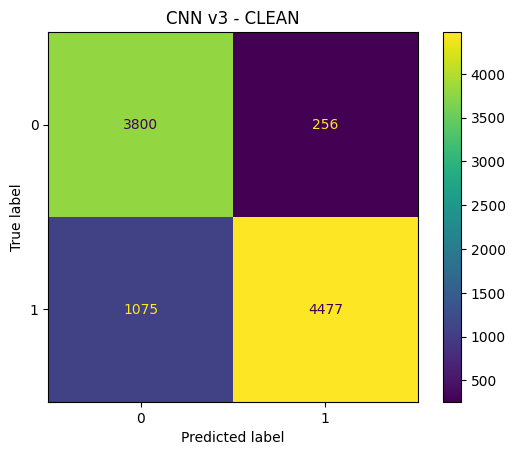

In [35]:
cm = confusion_matrix(yp_test_np, preds_p)
ConfusionMatrixDisplay(cm).plot()
plt.title("CNN v3 - CLEAN")
plt.show()

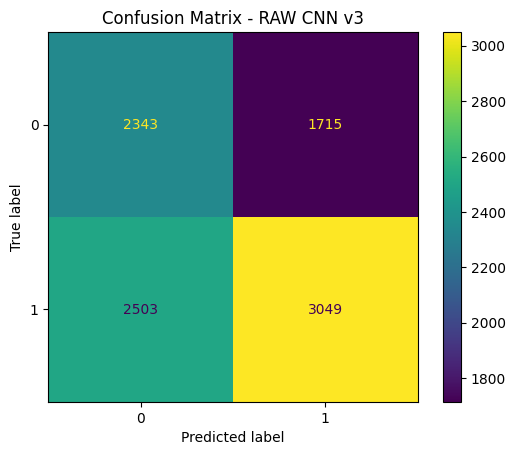

In [43]:
cm = confusion_matrix(true_r, preds_r)
ConfusionMatrixDisplay(cm).plot()
plt.title("Confusion Matrix - RAW CNN v3")
plt.show()

In [44]:
mis_r = np.where(preds_r != true_r)[0]
wrong_idx_r = idxr_test[mis_r]

wrong_samples_r = df_r.loc[wrong_idx_r].copy()
wrong_samples_r['predicted'] = preds_r[mis_r]

wrong_samples_r[['text', 'class', 'predicted']].head(10)

,text,class,predicted
11128,"I think the, Apple uses BSD without compensati...",0,1
30244,@DSwaggin6_ @_JustDavilaa @xaviee_21 @Quise414...,1,0
6519,"is a good option, but it's a partial solution....",0,1
41899,My niggah I was waiting all weekend to take th...,1,0
11242,I realize that you are a big mouthed liar who ...,0,1
3000,Big hair bitches &gt;&gt;&gt;&gt;&gt;&gt;&gt;&...,1,0
44833,&#8220;@AdderallHadMe: Adderall had me killing...,0,1
18184,"""Well, it will be hard for Iran to claim Israe...",0,1
26113,The big homie Drizzy threatening these hoes......,1,0
15606,&#8220;@PRAYINGFORHEAD: spongebob out here bea...,1,0


In [45]:
mis_p = np.where(preds_p != true_p)[0]
wrong_idx_p = idxp_test[mis_p]

wrong_samples_p = df_p.loc[wrong_idx_p].copy()
wrong_samples_p['predicted'] = preds_p[mis_p]

wrong_samples_p[['clean_text', 'class', 'predicted']].head(10)

,clean_text,class,predicted
43437,lookdumbfuck i am just pointing out the asshoi...,1,0
11115,my high school need to gon and throw a hood re...,1,0
40061,u coon cant wait to wear them oreo j,1,0
39434,rt my tbt i learn the english from that jabron...,1,0
35965,stop being a feminazi because you struggle at ...,1,0
37039,never ending horror of scum muslim oxfordabuse...,0,1
26746,eff it let go after the cripple,1,0
8547,but thanks for demonstrating for the millionth...,1,0
30785,hey teabagger the benghazi thing is a joke 13 ...,0,1
11012,oh my just go to show how young you are yes i ...,0,1


In [46]:
fp_r = wrong_samples_r[(wrong_samples_r['class'] == 0) & (wrong_samples_r['predicted'] == 1)]
fn_r = wrong_samples_r[(wrong_samples_r['class'] == 1) & (wrong_samples_r['predicted'] == 0)]

In [47]:
fp_p = wrong_samples_p[(wrong_samples_p['class'] == 0) & (wrong_samples_p['predicted'] == 1)]


In [48]:
fn_p = wrong_samples_p[(wrong_samples_p['class'] == 1) & (wrong_samples_p['predicted'] == 0)]

In [49]:
for _, row in fn_p.head(5).iterrows():
    print("TEXT:", row['clean_text'])
    print("TRUE:", row['class'], "| PRED:", row['predicted'])
    print("-" * 60)

TEXT: lookdumbfuck i am just pointing out the asshoies hypocrisy in calling out other people error if you want to defend him and suckhiscock then go get a private room together and have some decency
TRUE: 1 | PRED: 0
------------------------------------------------------------
TEXT: my high school need to gon and throw a hood reunion party everybody know we wa ghetto a hell
TRUE: 1 | PRED: 0
------------------------------------------------------------
TEXT: u coon cant wait to wear them oreo j
TRUE: 1 | PRED: 0
------------------------------------------------------------
TEXT: rt my tbt i learn the english from that jabroni big bird but i break his fucking neck
TRUE: 1 | PRED: 0
------------------------------------------------------------
TEXT: stop being a feminazi because you struggle at attracting the other sex stop starting dr
TRUE: 1 | PRED: 0
------------------------------------------------------------


In [50]:
for _, row in fp_p.head(5).iterrows():
    print("TEXT:", row['clean_text'])
    print("TRUE:", row['class'], "| PRED:", row['predicted'])
    print("-" * 60)

TEXT: never ending horror of scum muslim oxfordabuse oxford britain islam the rape and murder machine
TRUE: 0 | PRED: 1
------------------------------------------------------------
TEXT: hey teabagger the benghazi thing is a joke 13 benghazi under bush no hearing more on benghazi than real 911 attack
TRUE: 0 | PRED: 1
------------------------------------------------------------
TEXT: oh my just go to show how young you are yes i remember her and all her fancy hair colour a a tiny girl my daughter loved her
TRUE: 0 | PRED: 1
------------------------------------------------------------
TEXT: momma said no pussy cat inside my doghouse
TRUE: 0 | PRED: 1
------------------------------------------------------------
TEXT: rt 8220 moma said no pussy cat inside my dog house8221 thats what got bro nem locked inside the dog pound
TRUE: 0 | PRED: 1
------------------------------------------------------------


In [51]:
#testing on real data samples
#Step 1: load datasets and get basic info
df_1=pd.read_csv(r'C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\labeled_data.csv')
df_2=pd.read_csv(r'C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\train_E6oV3lV.csv')

In [52]:
import re
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

lemmatizer = WordNetLemmatizer()

def full_preprocess(text):
    text = str(text).lower()
    
    # Step 2: remove URLs, mentions, keep hashtag words
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    
    # Step 3: normalize elongated words
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    
    # Step 4: remove punctuation + extra spaces
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    
    # Step 5: lemmatization
    tokens = word_tokenize(text)
    text = " ".join([lemmatizer.lemmatize(word) for word in tokens])
    
    return text

In [53]:
df_1 = df_1.rename(columns={'tweet': 'text'})
df_1['label'] = df_1['class'].apply(lambda x: 0 if x == 2 else 1)

# preprocessed
df_1['clean_text'] = df_1['text'].apply(full_preprocess)

In [54]:
df_2 = df_2.rename(columns={'tweet': 'text'})

# preprocessed
df_2['clean_text'] = df_2['text'].apply(full_preprocess)

In [55]:
# --- MODEL R inputs ---
X1_raw_r   = pad_sequences(tokenizer_r.texts_to_sequences(df_1['text']), maxlen=100)
X1_clean_r = pad_sequences(tokenizer_r.texts_to_sequences(df_1['clean_text']), maxlen=100)

# --- MODEL P inputs ---
X1_raw_p   = pad_sequences(tokenizer_p.texts_to_sequences(df_1['text']), maxlen=100)
X1_clean_p = pad_sequences(tokenizer_p.texts_to_sequences(df_1['clean_text']), maxlen=100)

In [56]:
# --- MODEL R inputs ---
X2_raw_r   = pad_sequences(tokenizer_r.texts_to_sequences(df_2['text']), maxlen=100)
X2_clean_r = pad_sequences(tokenizer_r.texts_to_sequences(df_2['clean_text']), maxlen=100)

# --- MODEL P inputs ---
X2_raw_p   = pad_sequences(tokenizer_p.texts_to_sequences(df_2['text']), maxlen=100)
X2_clean_p = pad_sequences(tokenizer_p.texts_to_sequences(df_2['clean_text']), maxlen=100)

In [57]:
X1_raw_r   = torch.tensor(X1_raw_r, dtype=torch.long)
X1_clean_r = torch.tensor(X1_clean_r, dtype=torch.long)
X1_raw_p   = torch.tensor(X1_raw_p, dtype=torch.long)
X1_clean_p = torch.tensor(X1_clean_p, dtype=torch.long)

X2_raw_r   = torch.tensor(X2_raw_r, dtype=torch.long)
X2_clean_r = torch.tensor(X2_clean_r, dtype=torch.long)
X2_raw_p   = torch.tensor(X2_raw_p, dtype=torch.long)
X2_clean_p = torch.tensor(X2_clean_p, dtype=torch.long)

In [62]:
def predict_tensor(model, X, device, batch_size=32):
    model.eval()
    all_preds = []

    loader = DataLoader(X, batch_size=batch_size, shuffle=False)

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)

            outputs = model(batch)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()

            all_preds.extend(preds)

    return np.array(all_preds)

In [63]:
def evaluate_preds(y_true, y_pred, title=""):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print(f"\n=== {title} ===")
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")

In [64]:
y1 = df_1['label'].values
y2 = df_2['label'].values

In [68]:
print("\n=== DF1 RESULTS (CNN v3) ===")

# Model R
evaluate_preds(y1, predict_tensor(model_r, X1_raw_r, device),   "Model R on RAW")
evaluate_preds(y1, predict_tensor(model_r, X1_clean_r, device), "Model R on CLEAN")

# Model P
evaluate_preds(y1, predict_tensor(model_p, X1_raw_p, device),   "Model P on RAW")
evaluate_preds(y1, predict_tensor(model_p, X1_clean_p, device), "Model P on CLEAN")


=== DF1 RESULTS (CNN v3) ===

=== Model R on RAW ===
Accuracy:  0.5430
Precision: 0.8410
Recall:    0.5558
F1 Score:  0.6693

=== Model R on CLEAN ===
Accuracy:  0.5077
Precision: 0.8507
Recall:    0.4952
F1 Score:  0.6260

=== Model P on RAW ===
Accuracy:  0.7914
Precision: 0.9818
Recall:    0.7635
F1 Score:  0.8590

=== Model P on CLEAN ===
Accuracy:  0.9442
Precision: 0.9883
Recall:    0.9441
F1 Score:  0.9657


In [67]:
print("\n=== DF2 RESULTS (CNN v3) ===")

# Model R
evaluate_preds(y2, predict_tensor(model_r, X2_raw_r, device),   "Model R on RAW")
evaluate_preds(y2, predict_tensor(model_r, X2_clean_r, device), "Model R on CLEAN")

# Model P
evaluate_preds(y2, predict_tensor(model_p, X2_raw_p, device),   "Model P on RAW")
evaluate_preds(y2, predict_tensor(model_p, X2_clean_p, device), "Model P on CLEAN")


=== DF2 RESULTS (CNN v3) ===

=== Model R on RAW ===
Accuracy:  0.7252
Precision: 0.0841
Recall:    0.2948
F1 Score:  0.1308

=== Model R on CLEAN ===
Accuracy:  0.7467
Precision: 0.0797
Recall:    0.2475
F1 Score:  0.1206

=== Model P on RAW ===
Accuracy:  0.9100
Precision: 0.2272
Recall:    0.1178
F1 Score:  0.1551

=== Model P on CLEAN ===
Accuracy:  0.9080
Precision: 0.2315
Recall:    0.1343
F1 Score:  0.1700
